# Actividad 2 (10 %): Comparación de N-Grover con el tutorial de IBM y con el análisis manual

**Universidad de Antioquia** · Computación Cuántica · Práctica de Laboratorio No. 3: Algoritmo de Grover  
**Autores:** Carlos Andres Duran Paredes y Juan David Zapata Londoño

Este notebook resuelve la **Actividad 2** de la Práctica 3. Su organización sigue la del tutorial de IBM Quantum Learning
[*Quantum algorithms: Grover Search and applications*](https://quantum.cloud.ibm.com/learning/en/courses/utility-scale-quantum-computing/grovers-algorithm):
2.1 Preparación, *Step 1* (mapear el problema), los bloques 1: Inicialización, 2: Oracle y 3: Difusor,
2.2 la búsqueda con 2 qubits, 2.3 la simulación (*Step 3*) y el posprocesamiento (*Step 4*).
La diferencia es que aquí el circuito se construye con las funciones del notebook del curso
`N-Grover_AnyMark_2026.ipynb`, que generaliza el algoritmo a $n$ qubits y a cualquier estado marcado.

La actividad pide:

1. Analizar el notebook `N-Grover_AnyMark_2026.ipynb`.
2. Ejecutar su simulación para **2 qubits**.
3. Comparar esa ejecución con la del tutorial original de Qiskit.
4. Compararla con el análisis manual de cada etapa (Actividad 1).
5. Documentar y explicar las comparaciones.

El notebook original **no se modifica**. Sus funciones `Oracle` y `diffusion_operator` se copian aquí sin cambios,
y solo se ajustan los parámetros que dependen del número de qubits (`n`, `MarkState` y el número de iteraciones).

**Convención de qubits.** Qiskit usa orden *little-endian*: en un ket o en una cadena medida, $q_0$ es el dígito de la derecha.
Para 2 qubits, $|q_1q_0\rangle = |01\rangle$ significa $q_1=0$ y $q_0=1$. Es la misma convención de la Actividad 1.

In [ ]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime pylatexenc

## 1. Análisis del notebook `N-Grover_AnyMark_2026`

El notebook original tiene 12 celdas de código. Esto es lo que hace cada una:

| Celda | Contenido | Función |
|---|---|---|
| 0 | `QuantumCircuit`, `transpile`, `Statevector`, `numpy` | Importaciones |
| 1 | `n = 3`, `MarkState = '011'` | Número de qubits y estado marcado (MSB → LSB) |
| 2 | `Oracle(qc, target_state)` | Oracle de fase para **cualquier** estado marcado |
| 3 | `diffusion_operator(circuit)` | Difusor $H^{\otimes n}\,(\ldots)\,H^{\otimes n}$ |
| 4 | `grover_circuit.h(range(n))` | Inicialización: superposición uniforme |
| 5–6 | `Oracle(...)`, `diffusion_operator(...)` | Primera iteración de Grover |
| 7–8 | `Oracle(grover_circuit, '011')`, `diffusion_operator(...)` | Segunda iteración de Grover |
| 9 | `grover_circuit.draw('mpl')` | Dibujo del circuito |
| 10 | `Statevector(grover_circuit)` | Simulación exacta del vector de estado |
| 11 | Versiones | Qiskit 2.0.0, Qiskit Aer 0.17.0 y Python 3.13.2 en la ejecución guardada |

### ¿En qué mejora al tutorial?

1. **Sin qubit auxiliar.** El tutorial usa un auxiliar en $|-\rangle$ y una Toffoli. El signo llega a los datos por
   *retroceso de fase*. `Oracle` aplica el cambio de fase directamente sobre los $n$ qubits de datos, con una
   compuerta $Z$ multicontrolada construida como $H\cdot\mathrm{MCX}\cdot H$ sobre el último qubit.
2. **Cualquier estado marcado.** En el tutorial, el oracle de 2 qubits tiene escrito a mano `x(1)`, `ccx(0,1,2)` y `x(1)`,
   así que solo sirve para $|01\rangle$. `Oracle` recibe el estado como texto (`'011'`, `'1010'`, ...) y aplica $X$ en los
   qubits cuyo dígito es `0`. Así, cualquier estado se lleva a $|1\cdots1\rangle$, que es el único que la $Z$ multicontrolada
   cambia de signo. Después se deshacen esas $X$.
3. **Cualquier $n$.** Tanto `Oracle` como `diffusion_operator` usan `mcx` sobre `range(n-1)`, así que funcionan para cualquier $n\ge 2$.

### Lo que hay que ajustar para ejecutarlo con 2 qubits

- **Celda 1:** `n = 2` y un estado marcado de 2 dígitos. Se usa `MarkState = '01'`, el mismo estado que busca el tutorial,
  para que la comparación sea directa.
- **Celda 7:** la segunda llamada tiene el estado escrito a mano, `Oracle(grover_circuit, '011')`. Con `n = 2` esa celda falla,
  porque intenta usar el qubit 2, que no existe (se comprueba en la sección 6).
- **Celdas 7–8:** las dos iteraciones escritas a mano corresponden a $n=3$. Para $N = 2^2 = 4$ elementos basta **una**
  iteración, igual que en el tutorial (`num_iterations = 1`). Con dos iteraciones el resultado empeora (sección 6).
- **Simulación:** el notebook solo calcula el `Statevector`, sin medir. Para comparar con el tutorial, que reporta
  `{'001': 1024}`, aquí también se mide con `AerSimulator` y `Sampler`, igual que en el tutorial.

## 2. Implementación con el notebook N-Grover ($n = 2$)

### 2.1 Preparación

Importaciones del tutorial más `Statevector` y `Operator`, que se usan para obtener los estados y las matrices exactas.

In [2]:
%config InlineBackend.figure_format = 'svg' # Makes the images look nice

# importing Qiskit
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.quantum_info import Statevector, Operator

# import basic plot tools
from qiskit.visualization import plot_histogram

# Simulación (igual que en el tutorial, Step 3)
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import Sampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

import numpy as np

In [3]:
# Función auxiliar: escribe un vector de estado como suma de kets (solo los términos distintos de cero)
def mostrar(estado, etiqueta=""):
    amps = np.asarray(estado)
    nq = int(np.log2(len(amps)))
    terminos = [f"{a.real:+.4f}|{i:0{nq}b}⟩" for i, a in enumerate(amps) if abs(a) > 1e-9]
    print(f"{etiqueta:<34}" + "  ".join(terminos))

### Step 1: Map problem to quantum circuits and operators

Es el mismo problema del tutorial: en una lista de $N = 4$ elementos se busca el elemento cuyo índice es $|01\rangle$.
En el notebook N-Grover esto corresponde a la celda 1 con `n = 2` y `MarkState = '01'`.

In [4]:
# Celda 1 del notebook N-Grover, ajustada a 2 qubits
# Number of qubits
n = 2

# Choose target state according to the number of qubits.
MarkState = '01'  # Target state (MSB → LSB): q1 = 0, q0 = 1

### 1: Inicialización

En el notebook N-Grover la inicialización es la celda 4, `grover_circuit.h(range(n))`: una $H$ en cada qubit de datos.
No hay auxiliar, así que el circuito tiene solo 2 qubits:

$$
|\psi_{\text{init}}\rangle = H|0\rangle\otimes H|0\rangle = \tfrac12\big(|00\rangle+|01\rangle+|10\rangle+|11\rangle\big).
$$

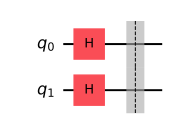

In [5]:
# Celda 4 del notebook N-Grover: superposición uniforme sobre los n qubits
initialization_circuit = QuantumCircuit(n)
initialization_circuit.h(range(n))
initialization_circuit.barrier()
initialization_circuit.draw(output="mpl")

In [6]:
mostrar(Statevector(initialization_circuit), "Estado después de la inicialización:")

Estado después de la inicialización:+0.5000|00⟩  +0.5000|01⟩  +0.5000|10⟩  +0.5000|11⟩


### 2: Oracle

Esta es la función `Oracle` de la celda 2, copiada sin cambios.

In [7]:
# Celda 2 del notebook N-Grover (sin cambios)
def Oracle(qc, target_state):
    # target_state: string like '1010' (MSB → LSB)
    n = len(target_state)

    # Step 1: Apply X to qubits where bit = 0
    for i, bit in enumerate(reversed(target_state)):  # Qiskit ordering
        if bit == '0':
            qc.x(i)

    # Step 2: Multi-controlled Z
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)

    # Step 3: Uncompute
    for i, bit in enumerate(reversed(target_state)):
        if bit == '0':
            qc.x(i)

**Qué compuertas genera para `'01'`.** `reversed('01')` recorre los dígitos desde $q_0$:

- $q_0$ tiene dígito `1`, así que no lleva $X$.
- $q_1$ tiene dígito `0`, así que lleva $X$.

Con `n = 2`, `mcx([0], 1)` es una CNOT de $q_0$ a $q_1$. El oracle queda así:

$$
U_f = X_1\,(H_1\,CX_{0\to1}\,H_1)\,X_1 = X_1\,CZ\,X_1 .
$$

$H$–CNOT–$H$ es una $CZ$, la misma identidad que aparece en los pasos 8–10 de la Actividad 1. $CZ$ cambia el signo solo de $|11\rangle$.
Las $X_1$ antes y después hacen que ese cambio de signo le toque a $|01\rangle$:

$$
U_f = I - 2|01\rangle\langle01| = \mathrm{diag}(1,-1,1,1).
$$

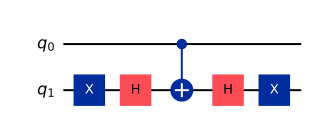

In [8]:
oracle_circuit = QuantumCircuit(n)
Oracle(oracle_circuit, MarkState)
oracle_circuit.draw(output="mpl")

In [9]:
U_oracle_ngrover = Operator(oracle_circuit).data
print("Matriz del oracle N-Grover (base |00>, |01>, |10>, |11>):")
print(np.round(U_oracle_ngrover.real, 3))
print("¿Es I - 2|01><01| ?", np.allclose(U_oracle_ngrover, np.diag([1, -1, 1, 1])))

Matriz del oracle N-Grover (base |00>, |01>, |10>, |11>):
[[ 1.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
¿Es I - 2|01><01| ? True


### 3: Operador de difusión

Esta es la función `diffusion_operator` de la celda 3, copiada sin cambios. Usa la variable global `n`.

In [10]:
# Celda 3 del notebook N-Grover (sin cambios)
# Define diffusion operator: H^n · (2|0⟩⟨0| - I) · H^n
def diffusion_operator(circuit):

    circuit.h(range(n))

    circuit.barrier()
    circuit.x(range(n))
    circuit.barrier()
    circuit.h(n - 1)
    circuit.mcx(list(range(n - 1)), n - 1)  # multi-controlled Z
    circuit.h(n - 1)
    circuit.barrier()
    circuit.x(range(n))

    circuit.barrier()
    circuit.h(range(n))

**Qué operador implementa.** $X^{\otimes n}\,\mathrm{MCZ}\,X^{\otimes n}$ cambia el signo solo de $|0\cdots0\rangle$, es decir,
es $I-2|0\rangle\langle0|$. Al rodearlo con $H^{\otimes n}$, y usando $|s\rangle = H^{\otimes n}|0\rangle$:

$$
H^{\otimes n}\big(I-2|0\rangle\langle0|\big)H^{\otimes n} = I-2|s\rangle\langle s| = -\big(2|s\rangle\langle s|-I\big).
$$

El comentario de la celda 3 dice $H^n(2|0\rangle\langle0|-I)H^n$, pero el circuito implementa el **negativo** de ese operador.
La diferencia es un factor $-1$, que es una fase global y no cambia ninguna probabilidad. Es la misma observación de la
Actividad 1 sobre el difusor del tutorial. Para $n=2$, la matriz es la $D_c$ calculada a mano en la Actividad 1:

$$
I-2|s\rangle\langle s| = \tfrac12\begin{pmatrix}1&-1&-1&-1\\-1&1&-1&-1\\-1&-1&1&-1\\-1&-1&-1&1\end{pmatrix}.
$$

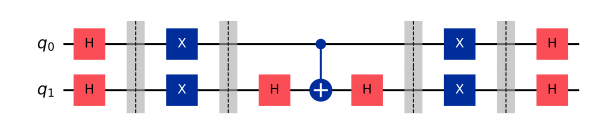

In [11]:
diffusion_circuit = QuantumCircuit(n)
diffusion_operator(diffusion_circuit)
diffusion_circuit.draw(output="mpl")

In [12]:
D_ngrover = Operator(diffusion_circuit).data
s = np.ones(2**n) / np.sqrt(2**n)                 # |s> = H^n |0>
D_manual = 0.5 * np.array([[ 1, -1, -1, -1],      # D_c de la Actividad 1
                           [-1,  1, -1, -1],
                           [-1, -1,  1, -1],
                           [-1, -1, -1,  1]])
print("Matriz del difusor N-Grover:")
print(np.round(D_ngrover.real, 3))
print("¿Es I - 2|s><s| ?          ", np.allclose(D_ngrover, np.eye(2**n) - 2 * np.outer(s, s)))
print("¿Es 2|s><s| - I ?          ", np.allclose(D_ngrover, 2 * np.outer(s, s) - np.eye(2**n)))
print("¿Coincide con D_c manual?  ", np.allclose(D_ngrover, D_manual))

Matriz del difusor N-Grover:
[[ 0.5 -0.5 -0.5 -0.5]
 [-0.5  0.5 -0.5 -0.5]
 [-0.5 -0.5  0.5 -0.5]
 [-0.5 -0.5 -0.5  0.5]]
¿Es I - 2|s><s| ?           True
¿Es 2|s><s| - I ?           False
¿Coincide con D_c manual?   True


### Step 2: Optimize for target hardware

Igual que en el tutorial, en simulación este paso se reduce a transpilar el circuito para el `AerSimulator`, y eso se hace en el *Step 3*.

### 2.2 Búsqueda de Grover con 2 qubits

El circuito se arma en el mismo orden que las celdas 4 a 6 del notebook N-Grover: inicialización, oracle y difusor, con las mismas barreras.
Para $N=4$ se usa **una** iteración, como en el tutorial (`num_iterations = 1`). Las celdas 7–8 del original no se ejecutan (ver sección 6).

In [13]:
# the number of iterations (igual que en el tutorial para 2 qubits)
num_iterations = 1

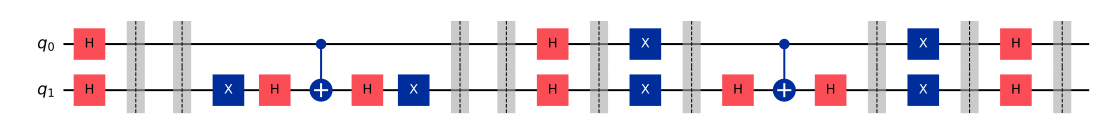

In [14]:
# Celdas 4 a 8 del notebook N-Grover, con el estado marcado como parámetro
grover_circuit = QuantumCircuit(n)

grover_circuit.h(range(n))
grover_circuit.barrier()

for i in range(0, num_iterations):
    grover_circuit.barrier()
    Oracle(grover_circuit, MarkState)      # en el original, la 2.ª iteración tenía '011' fijo
    grover_circuit.barrier()
    grover_circuit.barrier()
    diffusion_operator(grover_circuit)

# Visualize the circuit
grover_circuit.barrier()
grover_circuit.draw(output="mpl")

### 2.3 Experiment with Simulators

#### Simulación del vector de estado (celda 10 del notebook N-Grover)

In [15]:
state = Statevector(grover_circuit)
print(state)
state.draw('latex')  # Visual view of amplitudes

Statevector([ 2.02038958e-17+0.j, -1.00000000e+00+0.j, -3.92523115e-17+0.j,
             -9.25962153e-17+0.j],
            dims=(2, 2))


<IPython.core.display.Latex object>

El vector de estado final es $-|01\rangle$: toda la amplitud está en el estado marcado, con signo $-1$.
Ese signo es la fase global que introduce el difusor ($I-2|s\rangle\langle s|$ en lugar de $2|s\rangle\langle s|-I$), y no afecta la medición.

### Step 3: Executing the circuit.

Se mide el circuito y se ejecuta con el mismo código del tutorial: `AerSimulator`, transpilación con
`generate_preset_pass_manager` y `Sampler`. Se trabaja sobre una copia para conservar `grover_circuit` sin mediciones.

In [16]:
grover_circuit_meas = grover_circuit.copy()
grover_circuit_meas.measure_all()

# Define backend
backend = AerSimulator()

# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(grover_circuit_meas)

# Run the job
sampler = Sampler(mode=backend)
job = sampler.run([isa_qc])
result = job.result()

### Step 4: Post-processing the results.

{'01': 1024}


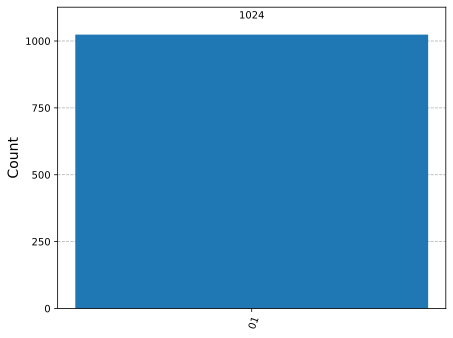

In [17]:
# Print the results
counts_ngrover = result[0].data.meas.get_counts()
print(counts_ngrover)

# Plot the counts in a histogram
plot_histogram(counts_ngrover)

Todas las ejecuciones dan `'01'`, que es el estado marcado $|q_1q_0\rangle = |01\rangle$. La probabilidad de éxito es 1.

## 3. Ejecución del tutorial original de Qiskit (sección 2.2)

Para comparar en las mismas condiciones, se ejecuta aquí el código de la sección 2.2 del tutorial, en el mismo entorno y con la misma versión de Qiskit.
Las funciones `initialization`, `oracle` y `diffusion` y las celdas de la sección 2.2 se copian del tutorial.
El único cambio es el nombre del circuito, `grover_circuit_tut` en lugar de `grover_circuit`, para no sobrescribir el de la sección 2.

In [18]:
# Funciones de la sección 2.1 del tutorial (sin cambios)
def initialization(circuit):
    # Initialization
    n = circuit.num_qubits
    # For input qubits
    for qubit in range(n - 1):
        circuit.h(qubit)
    # For the ancilla bit
    circuit.x(n - 1)
    circuit.h(n - 1)
    circuit.barrier()
    return circuit


def oracle(circuit):
    circuit.x(1)
    circuit.ccx(0, 1, 2)
    circuit.x(1)
    circuit.barrier()


def diffusion(circuit):
    input_qubits = circuit.num_qubits - 1
    circuit.h(range(0, input_qubits))
    circuit.x(range(0, input_qubits))
    circuit.h(input_qubits - 1)
    circuit.mcx([i for i in range(0, input_qubits - 1)], input_qubits - 1)
    circuit.h(input_qubits - 1)
    circuit.x(range(0, input_qubits))
    circuit.h(range(0, input_qubits))
    circuit.barrier()

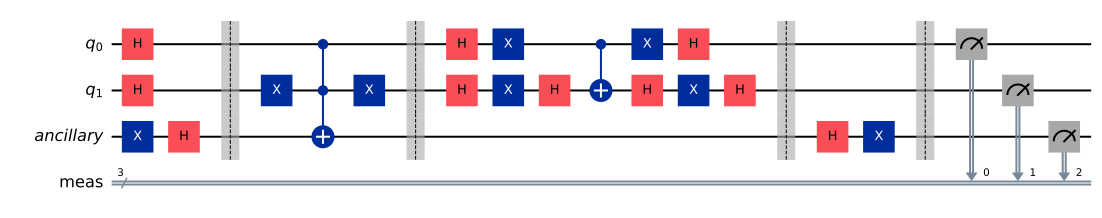

In [19]:
# Sección 2.2 del tutorial
n = 2
qr = QuantumRegister(n, "q")
anc = QuantumRegister(1, "ancillary")
meas = ClassicalRegister(3, "meas")
grover_circuit_tut = QuantumCircuit(qr, anc, meas)

# the number of iterations
num_iterations = 1

# Let's do Grover search
initialization(grover_circuit_tut)

for i in range(0, num_iterations):
    oracle(grover_circuit_tut)
    diffusion(grover_circuit_tut)

# Clear the ancilla bit
grover_circuit_tut.h(n)
grover_circuit_tut.x(n)
grover_circuit_tut.measure_all(add_bits=False)

grover_circuit_tut.draw(output="mpl", idle_wires=False)

{'001': 1024}


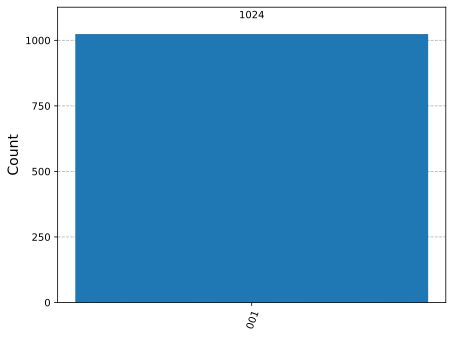

In [20]:
# Step 3 del tutorial
isa_qc_tut = pm.run(grover_circuit_tut)
job_tut = sampler.run([isa_qc_tut])
result_tut = job_tut.result()

# Step 4 del tutorial
counts_tut = result_tut[0].data.meas.get_counts()
print(counts_tut)
plot_histogram(counts_tut)

Se obtiene `{'001': 1024}`, el mismo resultado que muestra el tutorial. En la cadena `001` el dígito de la izquierda es el auxiliar
($q_2 = 0$, después de la limpieza) y los dos de la derecha son los datos, $q_1q_0 = 01$.

## 4. Comparación: N-Grover vs. tutorial original

### 4.1 Estructura de los circuitos

| Aspecto | Tutorial, sección 2.2 | N-Grover_AnyMark ($n=2$) |
|---|---|---|
| Qubits | 3: 2 de datos y 1 auxiliar | 2: solo datos |
| Inicialización | $H$ en $q_0,q_1$; $X$ y $H$ en el auxiliar, que queda en $\lvert-\rangle$ | $H$ en $q_0,q_1$ |
| Oracle | $X_1$, Toffoli $(q_0,q_1\to q_2)$, $X_1$ | $X_1$, $H_1$, $CX_{0\to1}$, $H_1$, $X_1$ |
| Cómo se marca el estado | Retroceso de fase: la Toffoli invierte el auxiliar $\lvert-\rangle$ y aparece un $-1$ | Fase directa: $H\cdot CX\cdot H = CZ$ sobre los datos |
| Estado marcado | Fijo en el código ($\lvert01\rangle$) | Parámetro `MarkState` (cualquiera) |
| Difusor | `diffusion`: $H,X,H,\mathrm{MCX},H,X,H$ sobre los datos | `diffusion_operator`: la misma secuencia, con barreras |
| Iteraciones | `num_iterations = 1` | 2 escritas a mano (pensadas para $n=3$); aquí se usa 1 |
| Limpieza del auxiliar | $H$ y $X$ en $q_2$ | No hace falta |
| Simulación original | `AerSimulator` + `Sampler`, 1024 disparos | `Statevector` exacto |
| Resultado | `{'001': 1024}` | `{'01': 1024}`; estado $-\lvert01\rangle$ |

La celda siguiente compara el tamaño de los dos circuitos antes y después de transpilar.

In [21]:
for nombre, qc, isa in [("Tutorial", grover_circuit_tut, isa_qc_tut),
                        ("N-Grover", grover_circuit_meas, isa_qc)]:
    ops = {k: v for k, v in qc.count_ops().items() if k not in ("barrier", "measure")}
    print(f"{nombre:9s} qubits={qc.num_qubits}  profundidad={qc.depth()}  compuertas={ops}")
    print(f"{'':9s} transpilado: profundidad={isa.depth()}  compuertas={dict(isa.count_ops())}")

Tutorial  qubits=3  profundidad=15  compuertas={'h': 10, 'x': 8, 'ccx': 1, 'cx': 1}
          transpilado: profundidad=9  compuertas={'u2': 4, 'barrier': 4, 'measure': 3, 'h': 2, 'x': 2, 'u1': 2, 'ccx': 1, 'cx': 1}
N-Grover  qubits=2  profundidad=14  compuertas={'h': 10, 'x': 6, 'cx': 2}
          transpilado: profundidad=12  compuertas={'barrier': 10, 'h': 8, 'x': 4, 'u2': 2, 'cx': 2, 'measure': 2}


Antes de transpilar, N-Grover usa un qubit menos, menos compuertas y ninguna Toffoli. Después de transpilar para `AerSimulator`,
el circuito de N-Grover tiene **mayor profundidad** que el del tutorial. La causa son las barreras: N-Grover pone una entre cada bloque
y varias dentro del difusor, y el transpilador no puede combinar compuertas a través de una barrera. El tutorial tiene menos barreras,
así que el transpilador fusiona varias $H$ y $X$ seguidas en compuertas `u1` y `u2`.

En el simulador la Toffoli se acepta tal cual. En hardware real no es nativa y se descompone en varias CNOT (6 en la descomposición estándar).
En cambio, el oracle de N-Grover para $n=2$ usa una sola CNOT.

### 4.2 El oracle y el difusor hacen lo mismo

**Oracle.** El oracle del tutorial actúa sobre 3 qubits. Para ver su efecto sobre los datos, se fija el auxiliar en $|-\rangle$
(que es como llega al oracle) y se calcula la matriz efectiva $4\times4$ sobre $|q_1q_0\rangle$:
$U_{\text{ef}} = V^\dagger U V$, con $V = |-\rangle\otimes I_4$. También se comprueba que el auxiliar sale igual que entró: $UV = VU_{\text{ef}}$.

**Difusor.** El difusor del tutorial solo actúa sobre $q_0$ y $q_1$, así que su matriz de 3 qubits debe ser $I_2\otimes D$,
donde $D$ es la matriz del difusor de N-Grover.

In [22]:
# Oracle del tutorial (3 qubits: q0, q1 datos; q2 auxiliar)
oracle_tut = QuantumCircuit(3)
oracle(oracle_tut)
U_tut = Operator(oracle_tut).data

menos = np.array([[1], [-1]]) / np.sqrt(2)        # |->
V = np.kron(menos, np.eye(4))                     # auxiliar (q2) a la izquierda: |->⊗|q1 q0>
U_ef = V.conj().T @ U_tut @ V

print("Oracle del tutorial, efecto sobre los datos con el auxiliar en |->:")
print(np.round(U_ef.real, 3))
print("¿El auxiliar sigue en |-> (U V = V U_ef)?   ", np.allclose(U_tut @ V, V @ U_ef))
print("¿Igual al oracle de N-Grover?               ", np.allclose(U_ef, U_oracle_ngrover))

# Difusor del tutorial
diff_tut = QuantumCircuit(3)
diffusion(diff_tut)
print("¿Difusor del tutorial = I_2 ⊗ D (N-Grover)? ",
      np.allclose(Operator(diff_tut).data, np.kron(np.eye(2), D_ngrover)))

Oracle del tutorial, efecto sobre los datos con el auxiliar en |->:
[[ 1.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]
¿El auxiliar sigue en |-> (U V = V U_ef)?    True
¿Igual al oracle de N-Grover?                True
¿Difusor del tutorial = I_2 ⊗ D (N-Grover)?  True


### 4.3 Estado final y conteos

Si se quita la medición del circuito del tutorial, su estado final debe ser $|0\rangle_{\text{aux}}\otimes(\text{estado final de N-Grover})$,
es decir, $|0\rangle\otimes(-|01\rangle) = -|001\rangle$. En `Statevector.tensor`, el operando de la derecha corresponde a los qubits de menor índice.

In [23]:
# Circuito del tutorial sin medición
tut_sin_medir = QuantumCircuit(QuantumRegister(2, "q"), QuantumRegister(1, "ancillary"))
initialization(tut_sin_medir)
oracle(tut_sin_medir)
diffusion(tut_sin_medir)
tut_sin_medir.h(2)
tut_sin_medir.x(2)

estado_tut = Statevector(tut_sin_medir)
mostrar(estado_tut, "Tutorial (3 qubits):")
mostrar(state, "N-Grover (2 qubits):")
print("¿Tutorial = |0>_aux ⊗ N-Grover?", estado_tut.equiv(Statevector.from_label('0').tensor(state)),
      "| igualdad exacta, con el signo:", np.allclose(estado_tut.data, Statevector.from_label('0').tensor(state).data))

Tutorial (3 qubits):              -1.0000|001⟩
N-Grover (2 qubits):              -1.0000|01⟩
¿Tutorial = |0>_aux ⊗ N-Grover? True | igualdad exacta, con el signo: True


Tutorial, solo datos q1q0: {'01': 1024}
N-Grover:                  {'01': 1024}


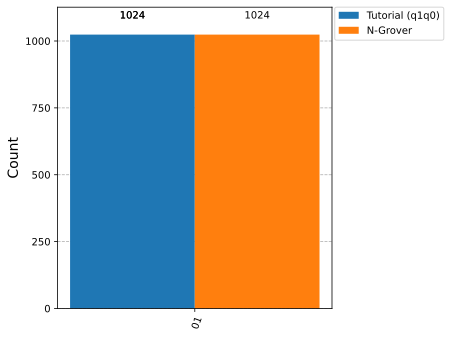

In [24]:
# Conteos de los datos q1q0: en el tutorial se descarta el dígito del auxiliar (el de la izquierda)
datos_tut = {}
for cadena, c in counts_tut.items():
    datos_tut[cadena[1:]] = datos_tut.get(cadena[1:], 0) + c

print("Tutorial, solo datos q1q0:", datos_tut)
print("N-Grover:                 ", counts_ngrover)
plot_histogram([datos_tut, counts_ngrover], legend=["Tutorial (q1q0)", "N-Grover"])

**Conclusión de la comparación con el tutorial.** Los dos circuitos tienen el mismo efecto sobre los qubits de datos.

- El oracle de N-Grover y el del tutorial, con el auxiliar en $|-\rangle$, dan la misma matriz $\mathrm{diag}(1,-1,1,1)$.
- Los difusores son la misma secuencia de compuertas.
- El estado final es $-|01\rangle$ en ambos casos. En el tutorial va acompañado del auxiliar en $|0\rangle$.
- Los dos simuladores entregan 1024 de 1024 disparos en el estado marcado.

La diferencia está en **cómo** se aplica la fase. El tutorial necesita un qubit más, una Toffoli y la limpieza final. N-Grover lo hace
sin auxiliar y con el estado marcado como parámetro, así que el mismo código sirve para cualquier $n$ y cualquier estado.

## 5. Comparación con el análisis manual (Actividad 1)

En la Actividad 1 se calcularon a mano los estados después de cada etapa del circuito del tutorial. Ese análisis lo desarrolló
Juan David Zapata Londoño y se publica por separado; aquí solo se usan sus resultados para comparar.
Los resultados de los datos $|q_1q_0\rangle$, con el auxiliar en $|-\rangle$ como factor, fueron:

| Etapa | Estado manual (Actividad 1) | Con el auxiliar |
|---|---|---|
| Inicialización ($\psi_2$) | $\tfrac12(\lvert00\rangle+\lvert01\rangle+\lvert10\rangle+\lvert11\rangle)$ | $\lvert-\rangle\otimes\cdots$ |
| Oracle ($\psi_5$) | $\tfrac12(\lvert00\rangle-\lvert01\rangle+\lvert10\rangle+\lvert11\rangle)$ | $\lvert-\rangle\otimes\cdots$ |
| Difusor ($\psi_{12}$) | $-\lvert01\rangle$ | $\lvert-\rangle\otimes\cdots$ |
| Limpieza ($\psi_{14}$) | $-\lvert01\rangle$ | $\lvert0\rangle\otimes\cdots$ |

### 5.1 Etapa por etapa

Se simula el circuito N-Grover hasta el final de cada etapa y se compara con los valores manuales.
También se simula el circuito del tutorial hasta la misma etapa y se comprueba que es $|-\rangle\otimes$ (estado de N-Grover).

In [25]:
n = 2  # vuelve al valor de N-Grover (diffusion_operator usa la variable global n)
r = 1 / np.sqrt(2)

# Valores manuales de la Actividad 1 (orden |00>, |01>, |10>, |11>)
manual = {
    "Inicialización": 0.5 * np.array([1,  1, 1, 1]),
    "Oracle":         0.5 * np.array([1, -1, 1, 1]),
    "Difusor":              np.array([0, -1, 0, 0]),
}

# Circuitos N-Grover parciales
ng = QuantumCircuit(n); ng.h(range(n))
etapas_ng = {"Inicialización": ng.copy()}
Oracle(ng, MarkState);       etapas_ng["Oracle"] = ng.copy()
diffusion_operator(ng);      etapas_ng["Difusor"] = ng.copy()

# Circuitos del tutorial parciales (sin limpieza ni medición)
tu = QuantumCircuit(3); initialization(tu)
etapas_tu = {"Inicialización": tu.copy()}
oracle(tu);                  etapas_tu["Oracle"] = tu.copy()
diffusion(tu);               etapas_tu["Difusor"] = tu.copy()

aux_menos = Statevector(np.array([r, -r]))
print(f"{'Etapa':16s}{'Manual (Act. 1)':>36s}{'N-Grover (simulado)':>36s}   ¿Coincide?  ¿Tutorial = |->⊗N-Grover?")
for etapa in manual:
    sv_ng = Statevector(etapas_ng[etapa])
    sv_tu = Statevector(etapas_tu[etapa])
    print(f"{etapa:16s}{str(np.round(manual[etapa], 3)):>36s}{str(np.round(sv_ng.data.real, 3)):>36s}"
          f"   {str(np.allclose(sv_ng.data, manual[etapa])):10s}  {np.allclose(sv_tu.data, aux_menos.tensor(sv_ng).data)}")

Etapa                                Manual (Act. 1)                 N-Grover (simulado)   ¿Coincide?  ¿Tutorial = |->⊗N-Grover?
Inicialización                     [0.5 0.5 0.5 0.5]                   [0.5 0.5 0.5 0.5]   True        True
Oracle                         [ 0.5 -0.5  0.5  0.5]               [ 0.5 -0.5  0.5  0.5]   True        True
Difusor                                [ 0 -1  0  0]                   [ 0. -1. -0. -0.]   True        True


Los tres estados simulados coinciden **exactamente** con los manuales, incluido el signo $-1$ del final.
Además, en cada etapa el estado del tutorial es $|-\rangle\otimes$ (estado de N-Grover). Esto confirma que el auxiliar del tutorial
solo sirve para producir el cambio de fase y no queda entrelazado con los datos.

### 5.2 Dentro del oracle

Aquí los dos circuitos usan compuertas distintas, así que solo se pueden comparar al principio y al final de la etapa.
En la Actividad 1 (pasos 3–5), el tutorial usa $X_1$, la Toffoli con el auxiliar y $X_1$. N-Grover usa $X_1$, $H_1$, $CX_{0\to1}$, $H_1$ y $X_1$.
Los estados intermedios de N-Grover son:

In [26]:
pasos_oracle = [
    ("X en q1",           lambda c: c.x(1)),
    ("H en q1",           lambda c: c.h(1)),
    ("CX q0 -> q1 (mcx)", lambda c: c.mcx([0], 1)),
    ("H en q1",           lambda c: c.h(1)),
    ("X en q1",           lambda c: c.x(1)),
]
c = QuantumCircuit(n); c.h(range(n))
mostrar(Statevector(c), "Entrada (inicialización):")
for etiqueta, capa in pasos_oracle:
    capa(c)
    mostrar(Statevector(c), f"Después de {etiqueta}:")
print("¿Las capas reproducen la función Oracle?", Operator(c).equiv(Operator(etapas_ng["Oracle"])))

Entrada (inicialización):         +0.5000|00⟩  +0.5000|01⟩  +0.5000|10⟩  +0.5000|11⟩
Después de X en q1:               +0.5000|00⟩  +0.5000|01⟩  +0.5000|10⟩  +0.5000|11⟩
Después de H en q1:               +0.7071|00⟩  +0.7071|01⟩
Después de CX q0 -> q1 (mcx):     +0.7071|00⟩  +0.7071|11⟩
Después de H en q1:               +0.5000|00⟩  +0.5000|01⟩  +0.5000|10⟩  -0.5000|11⟩
Después de X en q1:               +0.5000|00⟩  -0.5000|01⟩  +0.5000|10⟩  +0.5000|11⟩
¿Las capas reproducen la función Oracle? True


- Después de la primera $X_1$, el estado no cambia, porque $X|+\rangle = |+\rangle$. Es lo mismo que se vio en el paso 3 de la Actividad 1.
- $H_1$ y la CNOT generan estados intermedios que no existen en el circuito del tutorial.
- La segunda $H_1$ completa la $CZ$, y la última $X_1$ deja el resultado del paso 5 manual: $\tfrac12(|00\rangle-|01\rangle+|10\rangle+|11\rangle)$.

En el tutorial el signo llega por retroceso de fase desde el auxiliar. En N-Grover llega por la $CZ$ directamente sobre los datos.

### 5.3 Dentro del difusor, capa por capa ($\psi_5\to\psi_{12}$)

El difusor de N-Grover es la misma secuencia de compuertas que el del tutorial. Por eso sus estados intermedios deben coincidir con los
pasos 6 a 12 del documento paso a paso de la Actividad 1, tomando solo los datos (sin el factor $|-\rangle$).

In [27]:
capas_difusor = [
    ("ψ6:  H en q1 y q0", lambda c: c.h([0, 1]), 0.5 * np.array([1,  1, -1,  1])),
    ("ψ7:  X en q1 y q0", lambda c: c.x([0, 1]), 0.5 * np.array([1, -1,  1,  1])),
    ("ψ8:  H en q1",      lambda c: c.h(1),        r * np.array([1,  0,  0, -1])),
    ("ψ9:  CX q0 -> q1",  lambda c: c.mcx([0], 1), r * np.array([1, -1,  0,  0])),
    ("ψ10: H en q1",      lambda c: c.h(1),      0.5 * np.array([1, -1,  1, -1])),
    ("ψ11: X en q1 y q0", lambda c: c.x([0, 1]), 0.5 * np.array([-1, 1, -1,  1])),
    ("ψ12: H en q1 y q0", lambda c: c.h([0, 1]),       np.array([0, -1,  0,  0])),
]
c = etapas_ng["Oracle"].copy()
print(f"{'Capa':20s}{'Manual (paso a paso)':>34s}{'Simulado':>34s}   ¿Coincide?")
for etiqueta, capa, valor_manual in capas_difusor:
    capa(c)
    sv = Statevector(c).data
    print(f"{etiqueta:20s}{str(np.round(valor_manual, 3)):>34s}{str(np.round(sv.real, 3)):>34s}   {np.allclose(sv, valor_manual)}")

d = QuantumCircuit(n)
for _, capa, _ in capas_difusor:
    capa(d)
print("¿Las 7 capas reproducen diffusion_operator?", Operator(d).equiv(Operator(diffusion_circuit)))

Capa                              Manual (paso a paso)                          Simulado   ¿Coincide?
ψ6:  H en q1 y q0                [ 0.5  0.5 -0.5  0.5]             [ 0.5  0.5 -0.5  0.5]   True
ψ7:  X en q1 y q0                [ 0.5 -0.5  0.5  0.5]             [ 0.5 -0.5  0.5  0.5]   True
ψ8:  H en q1             [ 0.707  0.     0.    -0.707]     [ 0.707  0.    -0.    -0.707]   True
ψ9:  CX q0 -> q1         [ 0.707 -0.707  0.     0.   ]     [ 0.707 -0.707 -0.     0.   ]   True
ψ10: H en q1                     [ 0.5 -0.5  0.5 -0.5]             [ 0.5 -0.5  0.5 -0.5]   True
ψ11: X en q1 y q0                [-0.5  0.5 -0.5  0.5]             [-0.5  0.5 -0.5  0.5]   True
ψ12: H en q1 y q0                        [ 0 -1  0  0]                 [ 0. -1. -0. -0.]   True
¿Las 7 capas reproducen diffusion_operator? True


Las siete capas coinciden con el cálculo manual. Se ven los mismos efectos descritos en la Actividad 1:

- En $\psi_8$ dos amplitudes se cancelan y los datos quedan en un estado de Bell, $\tfrac{1}{\sqrt2}(|00\rangle-|11\rangle)$.
- Los pasos 8–10 ($H$–CNOT–$H$) cambian el signo solo de $|11\rangle$.
- En $\psi_{12}$ toda la amplitud está en $|01\rangle$.

### 5.4 Probabilidades: manual, vector de estado y muestreo

In [28]:
p_manual = np.array([0, 1, 0, 0])                       # Actividad 1: P(01) = |-1|^2 = 1
p_sv = state.probabilities()                            # Statevector (celda 10 de N-Grover)
shots = sum(counts_ngrover.values())
p_shots = np.array([counts_ngrover.get(f"{i:02b}", 0) / shots for i in range(4)])

print(f"{'Estado':8s}{'Manual':>10s}{'Statevector':>14s}{'Sampler (' + str(shots) + ' disparos)':>26s}")
for i in range(4):
    print(f"|{i:02b}>    {p_manual[i]:>10.3f}{p_sv[i]:>14.3f}{p_shots[i]:>26.3f}")

Estado      Manual   Statevector   Sampler (1024 disparos)
|00>         0.000         0.000                     0.000
|01>         1.000         1.000                     1.000
|10>         0.000         0.000                     0.000
|11>         0.000         0.000                     0.000


Las tres columnas coinciden. El muestreo da exactamente 1 porque la probabilidad teórica de $|01\rangle$ es 1, así que no hay variación estadística.
En el `Statevector` sí se ve el signo $-1$ (amplitud $-1$ en $|01\rangle$), igual que en el análisis manual. Al medir ese signo desaparece, porque $|-1|^2 = 1$.

## 6. ¿Qué pasa si se ejecuta el notebook con sus dos iteraciones?

El notebook N-Grover tiene dos iteraciones escritas a mano (celdas 5–8), y la segunda tiene el estado `'011'` fijo.

**Celda 7 tal como está.** Con `n = 2`, `Oracle(grover_circuit, '011')` intenta usar el qubit 2, que no existe:

In [29]:
prueba = QuantumCircuit(n)
try:
    Oracle(prueba, '011')   # celda 7 del original, sin cambios
except Exception as e:
    print(type(e).__name__, ":", e)

CircuitError : 'Index 2 out of range for size 2.'


**Dos iteraciones con el estado correcto.** Si en la celda 7 se cambia `'011'` por `MarkState`, el circuito se ejecuta,
pero el resultado empeora. La explicación geométrica: con $N=4$ y un solo estado marcado, $\sin\theta = 1/\sqrt{N} = 1/2$, es decir $\theta = 30^\circ$.
Después de $k$ iteraciones la amplitud del estado marcado es $\sin\big((2k+1)\theta\big)$:

| $k$ | $(2k+1)\theta$ | $P(\lvert01\rangle)=\sin^2((2k+1)\theta)$ |
|---|---|---|
| 0 | $30^\circ$ | $0.25$ |
| 1 | $90^\circ$ | $1$ |
| 2 | $150^\circ$ | $0.25$ |
| 3 | $210^\circ$ | $0.25$ |

Con una iteración el estado llega exactamente a $|01\rangle$. Una segunda iteración lo pasa de largo y vuelve a una probabilidad de $1/4$.

In [30]:
theta = np.arcsin(1 / np.sqrt(2**n))
for k in range(4):
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for _ in range(k):
        Oracle(qc, MarkState)
        diffusion_operator(qc)
    sv = Statevector(qc)
    print(f"k = {k}:  P(|01>) simulada = {sv.probabilities()[1]:.3f}   "
          f"teórica = {np.sin((2*k + 1) * theta)**2:.3f}   amplitudes = {np.round(sv.data.real, 3)}")

k = 0:  P(|01>) simulada = 0.250   teórica = 0.250   amplitudes = [0.5 0.5 0.5 0.5]
k = 1:  P(|01>) simulada = 1.000   teórica = 1.000   amplitudes = [ 0. -1. -0. -0.]
k = 2:  P(|01>) simulada = 0.250   teórica = 0.250   amplitudes = [-0.5  0.5 -0.5 -0.5]
k = 3:  P(|01>) simulada = 0.250   teórica = 0.250   amplitudes = [0.5 0.5 0.5 0.5]


{'01': 251, '10': 255, '00': 230, '11': 288}


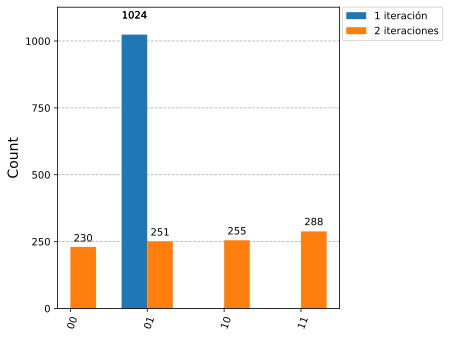

In [31]:
# Muestreo con dos iteraciones (celdas 5 a 8 con MarkState en lugar de '011')
qc2 = QuantumCircuit(n)
qc2.h(range(n))
for _ in range(2):
    Oracle(qc2, MarkState)
    diffusion_operator(qc2)
qc2.measure_all()

counts_2it = sampler.run([pm.run(qc2)]).result()[0].data.meas.get_counts()
print(counts_2it)
plot_histogram([counts_ngrover, counts_2it], legend=["1 iteración", "2 iteraciones"])

Con dos iteraciones los cuatro estados quedan con probabilidad $1/4$. El histograma reparte los 1024 disparos de forma aproximadamente uniforme,
con la variación estadística propia del muestreo. Por eso, para 2 qubits se debe usar **una** iteración, como en el tutorial.
Las dos iteraciones del notebook original son las adecuadas para $n = 3$, que es el caso para el que está escrito.

---

## 7. Conclusiones

1. **El notebook N-Grover generaliza el tutorial sin cambiar el algoritmo.** Para $n=2$ y `MarkState = '01'`, su oracle es
   $I-2|01\rangle\langle01|$ y su difusor es $I-2|s\rangle\langle s|$. Son las mismas matrices que el circuito del tutorial aplica sobre
   los qubits de datos y las mismas que se obtuvieron a mano en la Actividad 1.
2. **La diferencia está en el oracle.** El tutorial marca el estado con un auxiliar en $|-\rangle$ y una Toffoli (retroceso de fase), y
   tiene el estado marcado escrito en el código. N-Grover marca el estado directamente con una $Z$ multicontrolada ($H\cdot\mathrm{MCX}\cdot H$),
   rodeada de $X$ en los qubits cuyo dígito es 0. Por eso no necesita auxiliar ni limpieza y sirve para cualquier estado y cualquier $n$.
3. **Los resultados coinciden.** El tutorial da `{'001': 1024}` y N-Grover da `{'01': 1024}`. Son el mismo resultado sobre los datos
   $q_1q_0 = 01$; el `0` adicional del tutorial es el auxiliar ya limpio. Los vectores de estado cumplen
   $|\psi_{\text{tutorial}}\rangle = |0\rangle\otimes|\psi_{\text{N-Grover}}\rangle = -|001\rangle$.
4. **El análisis manual queda confirmado.** Los estados simulados al final de cada etapa coinciden con los de la Actividad 1:
   - Inicialización: $\tfrac12(1,1,1,1)$.
   - Oracle: $\tfrac12(1,-1,1,1)$.
   - Difusor: $(0,-1,0,0)$.

   También coinciden las siete capas intermedias del difusor ($\psi_6$ a $\psi_{12}$). El signo $-1$ final aparece en la simulación
   igual que en el cálculo manual. Se debe a que el difusor implementa $-(2|s\rangle\langle s|-I)$, y no afecta la medición.
5. **Para usar el notebook con 2 qubits hay que ajustar las iteraciones.**
   - Las dos iteraciones escritas a mano corresponden a $n=3$.
   - La celda 7 tiene el estado `'011'` fijo y falla con $n=2$.
   - Para $N=4$ la cantidad correcta es una iteración. Con dos, la probabilidad de éxito baja de 1 a $1/4$.

### Versiones

In [32]:
from qiskit import __version__ as qiskit_version
from qiskit_aer import __version__ as aer_version
from qiskit_ibm_runtime import __version__ as runtime_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('Qiskit_Aer Version:', aer_version)
print('Qiskit_IBM_Runtime Version:', runtime_version)
print('Python Version:', python_version())

Qiskit Version:

 2.5.2
Qiskit_Aer Version: 0.18.2
Qiskit_IBM_Runtime Version: 0.51.0
Python Version: 3.13.14
